# Arsenal Transformer: pitch-type classification for unseen pitchers

**Goal:** classify Statcast pitch types (FF, SI, FC, SL, ST, SV, CU, KC, CH, FS) for pitchers the model has **never seen**, by showing it the target pitch together with a sample of the same pitcher's other pitches. The context pitches contain features only, never labels, so the model has to work out the pitcher's arsenal itself (where his fastball is, how his breaking balls separate).

We compare it against a gradient-boosting baseline with hand-built fastball-relative features.

**Steps**
1. Pull and clean Statcast data (2023–2025) with `pybaseball`
2. Baseline: LightGBM with pitcher-relative features
3. Dataset: (target pitch, context set) samples
4. Model: Arsenal Transformer
5. Training
6. Evaluation: test metrics, confusion matrix, cold-start curve, disagreements

**Runtime:** the first data pull takes a while (three seasons). It's cached to disk, so later runs are fast. A GPU helps for step 5. For a quick check, set `EPOCHS = 1` and `SAMPLES_PER_EPOCH = 50_000` first.

In [ ]:
# Uncomment on first run (or in Colab):
!pip install pybaseball lightgbm torch pyarrow scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.1/426.1 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.6/455.6 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 71.4 MB/s eta 0:00:00


## Settings

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (accuracy_score, classification_report,confusion_matrix, f1_score)
from torch import nn
from torch.utils.data import DataLoader, Dataset, RandomSampler, Subset

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

SEASONS = [2024, 2025,2026]   # 2023+ keeps the sweeper (ST) label consistent
SEED = 42

# Savant pitch_type -> training label. Codes not listed are dropped
# (knuckleball, eephus, screwball, pitchouts, intentional balls, unknown).
LABEL_MAP = {
    "FF": "FF", "SI": "SI", "FC": "FC",                # fastballs
    "SL": "SL", "ST": "ST", "SV": "SV",                # slider, sweeper, slurve
    "CU": "CU", "CS": "CU", "KC": "KC",                # curveballs (slow curve -> CU)
    "CH": "CH", "FS": "FS", "FO": "FS",                # offspeed (forkball -> FS)
}
MERGE_SWEEPER_INTO_SLIDER = False

RAW_COLS = [
    "pitcher", "p_throws", "game_date", "game_pk", "game_year", "game_type",
    "at_bat_number", "pitch_number", "pitch_type",
    "release_speed", "release_spin_rate", "spin_axis",
    "pfx_x", "pfx_z", "release_pos_x", "release_pos_z", "release_extension",
    "arm_angle", "vx0", "vz0", "ax", "az",
]
PITCH_FEATURES = [
    "release_speed", "release_spin_rate", "spin_axis_sin", "spin_axis_cos",
    "pfx_x_in", "pfx_z_in", "release_pos_x", "release_pos_z", "release_extension",
    "arm_angle", "arm_angle_missing", "vx0", "vz0", "ax", "az",
]

# Training hyperparameters
EPOCHS = 8
SAMPLES_PER_EPOCH = 600_000
BATCH_SIZE = 512
LR = 1e-3
CTX_MAX = 100
D_MODEL = 128
WORKERS = 0           # keep 0 in Jupyter on Windows/macOS; 4+ is fine on Linux/Colab
EVAL_SUBSAMPLE = 150_000
PAST_ONLY = False     # True = evaluate with context from earlier pitches only (live setting)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
torch.manual_seed(SEED)
print("Device:", DEVICE)

Device: cuda


## Step 1: Pull and clean the data

Each season is downloaded once and cached to `data/`. We keep regular-season games only.

In [ ]:
DATA_DIR

PosixPath('data')

In [ ]:
def save_df(df, name):
    try:
        df.to_parquet(DATA_DIR / f"{name}.parquet", index=False)
    except ImportError:                      # no pyarrow -> pickle
        df.to_pickle(DATA_DIR / f"{name}.pkl")


def load_df(name):
    pq, pk = DATA_DIR / f"{name}.parquet", DATA_DIR / f"{name}.pkl"
    if pq.exists():
        return pd.read_parquet(pq)
    if pk.exists():
        return pd.read_pickle(pk)
    return None


def pull_season(year):
    df = load_df(f"raw_{year}")
    if df is not None:
        print(f"{year}: using cached file ({len(df):,} rows)")
        return df
    #using pybaseball
    from pybaseball import cache, statcast
    cache.enable()
    df = statcast(start_dt=f"{year}-03-15", end_dt=f"{year}-10-05")
    df = df[[c for c in RAW_COLS if c in df.columns]]
    save_df(df, f"raw_{year}")
    print(f"{year}: {len(df):,} pitches downloaded")
    return df


raw = pd.concat([pull_season(y) for y in SEASONS], ignore_index=True)

This is a large query, it may take a moment to complete


  0%|          | 0/205 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  0%|          | 1/205 [00:06<20:53,  6.14s/it]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch excep

2024: 751,131 pitches downloaded
This is a large query, it may take a moment to complete


  0%|          | 0/205 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  0%|          | 1/205 [00:07<24:05,  7.09s/it]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  1%|          | 2/205 [00:07<11:28,  3.39s/it]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_da

2025: 761,524 pitches downloaded
This is a large query, it may take a moment to complete


  0%|          | 0/205 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  0%|          | 1/205 [00:07<26:39,  7.84s/it]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch excep

2026: 757,393 pitches downloaded


In [ ]:
from google.colab import drive
import shutil
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/arsenal_transformer")
shutil.copytree("/content/data", PROJECT_DIR / "data", dirs_exist_ok=True)
shutil.copytree("/content/outputs", PROJECT_DIR / "outputs", dirs_exist_ok=True)

print(list((PROJECT_DIR / "data").iterdir()))

Mounted at /content/drive
[PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2025.parquet'), PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2026.parquet'), PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2024.parquet')]


[PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2024.parquet'), PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2025.parquet'), PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2026.parquet')]


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/arsenal_transformer")
DATA_DIR = PROJECT_DIR / "data";    DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_DIR / "outputs";  OUT_DIR.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
print(list(DATA_DIR.iterdir()))

[PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2024.parquet'), PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2025.parquet'), PosixPath('/content/drive/MyDrive/arsenal_transformer/data/raw_2026.parquet')]


In [ ]:
raw = pd.concat(
    [pd.read_parquet(DATA_DIR / f"raw_{y}.parquet") for y in SEASONS],
    ignore_index=True)
print(f"{len(raw):,} rows")

2,270,048 rows


In [ ]:
raw.head()

,pitcher,p_throws,game_date,game_pk,game_year,game_type,at_bat_number,pitch_number,pitch_type,release_speed,...,pfx_x,pfx_z,release_pos_x,release_pos_z,release_extension,arm_angle,vx0,vz0,ax,az
0,596133,R,2024-10-05,775334,2024,D,80,5,CH,88.9,...,-1.17,0.54,-1.66,5.67,6.0,46.5,5.135634,-3.58521,-14.160204,-25.575466
1,596133,R,2024-10-05,775334,2024,D,80,4,FF,95.7,...,-0.56,1.56,-1.43,5.83,5.9,48.6,7.477183,-1.066465,-9.113527,-12.007497
2,596133,R,2024-10-05,775334,2024,D,80,3,CH,87.8,...,-1.28,0.38,-1.65,5.64,6.1,48.2,5.560977,-4.600058,-15.186889,-27.208939
3,596133,R,2024-10-05,775334,2024,D,80,2,FF,95.6,...,-0.86,1.63,-1.52,5.73,6.1,48.4,5.733364,-8.753658,-12.473109,-9.282716
4,596133,R,2024-10-05,775334,2024,D,80,1,FF,94.6,...,-0.94,1.76,-1.52,5.75,6.1,48.9,4.471275,-9.561998,-12.929949,-8.003131


In [ ]:
raw.shape

(2270048, 22)

**Cleaning steps**
- Map Savant codes to our labels and drop rare or meaningless ones.
- **Mirror left-handers** so both hands share one feature space: horizontal values flip sign and the spin axis reflects across the vertical.
- **Encode spin axis as sin/cos**, because it's circular (0° = 360°).
- Convert movement to inches.
- Sort each pitcher's pitches in time order. One "arsenal" (`group_id`) = one pitcher in one season.

In [ ]:
def clean(df):
    df = df.copy()
    for col in RAW_COLS:              # newer columns (e.g. arm_angle) may be missing
        if col not in df.columns:
            df[col] = np.nan

    df = df[df["game_type"] == "R"]
    df["label"] = df["pitch_type"].map(LABEL_MAP)
    if MERGE_SWEEPER_INTO_SLIDER:
        df.loc[df["label"] == "ST", "label"] = "SL"
    df = df[df["label"].notna()]

    num_cols = ["release_speed", "release_spin_rate", "spin_axis", "pfx_x", "pfx_z",
                "release_pos_x", "release_pos_z", "release_extension", "arm_angle",
                "vx0", "vz0", "ax", "az"]
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
    df = df.dropna(subset=[c for c in num_cols if c != "arm_angle"] + ["pitcher", "p_throws"])

    lefty = df["p_throws"] == "L"
    for col in ["pfx_x", "release_pos_x", "vx0", "ax"]:
        df.loc[lefty, col] = -df.loc[lefty, col]
    df.loc[lefty, "spin_axis"] = (360 - df.loc[lefty, "spin_axis"]) % 360

    rad = np.deg2rad(df["spin_axis"])
    df["spin_axis_sin"], df["spin_axis_cos"] = np.sin(rad), np.cos(rad)
    df["pfx_x_in"], df["pfx_z_in"] = df["pfx_x"] * 12, df["pfx_z"] * 12
    df["arm_angle_missing"] = df["arm_angle"].isna().astype(np.float32)

    df["game_date"] = pd.to_datetime(df["game_date"])
    df["game_year"] = df["game_date"].dt.year
    df = df.sort_values(["pitcher", "game_date", "game_pk", "at_bat_number", "pitch_number"])
    df["group_id"] = df.groupby(["pitcher", "game_year"]).ngroup()
    df = df[df.groupby("group_id")["group_id"].transform("size") >= 20]
    return df.reset_index(drop=True)

**Split by pitcher.** Every pitcher lands in exactly one of train / val / test, so test pitchers are truly unseen and neither model can memorize their arsenals.

In [ ]:
def split_by_pitcher(df, val_frac=0.15, test_frac=0.15):
    rng = np.random.default_rng(SEED)
    pitchers = df["pitcher"].unique()
    rng.shuffle(pitchers)
    n_test, n_val = int(len(pitchers) * test_frac), int(len(pitchers) * val_frac)
    split = pd.Series("train", index=pitchers)
    split.iloc[:n_test] = "test"
    split.iloc[n_test:n_test + n_val] = "val"
    df["split"] = df["pitcher"].map(split)

    med = df.loc[df["split"] == "train", "arm_angle"].median()   # train-only statistic
    df["arm_angle"] = df["arm_angle"].fillna(0.0 if np.isnan(med) else med)
    return df


df = split_by_pitcher(clean(raw))
del raw

CLASSES = sorted(df["label"].unique())
TO_IDX = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df["label"].map(TO_IDX)

print(f"{len(df):,} pitches | {df['pitcher'].nunique():,} pitchers | "
      f"{df['group_id'].nunique():,} pitcher-seasons")
display(df.groupby("split")["pitcher"].nunique().rename("pitchers").to_frame())
display(df["label"].value_counts(normalize=True).round(3).to_frame())

/tmp/ipykernel_386/2398446702.py:4: UserWarning: you are shuffling a 'IntegerArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(pitchers)


2,118,922 pitches | 1,175 pitchers | 2,401 pitcher-seasons


,pitchers
split,
test,176
train,823
val,176


,proportion
label,
FF,0.316
SI,0.160
SL,0.142
CH,0.106
FC,0.079
ST,0.078
CU,0.065
FS,0.033
KC,0.017


## Step 2: Baseline (gradient boosting + pitcher-relative features)

Each pitcher-season gets a **reference** built *without labels*: the average of his hardest-thrown pitches (top 10% by velocity). Using `pitch_type` to find his fastball would leak the answer, since test pitchers' labels are unknown. Every pitch then gets differences from that reference (speed, movement, spin, release).

In [ ]:
def add_relative_features(df):
    df = df.copy()
    g = df.groupby("group_id")
    hard = df["release_speed"] >= g["release_speed"].transform("quantile", 0.9)
    ref_cols = ["release_speed", "release_spin_rate", "pfx_x_in", "pfx_z_in",
                "release_pos_x", "release_pos_z", "release_extension",
                "spin_axis_sin", "spin_axis_cos"]
    ref = df[hard].groupby("group_id")[ref_cols].mean().add_prefix("ref_")
    df = df.join(ref, on="group_id")

    rel = []
    for c in ref_cols[:7]:
        df[f"d_{c}"] = df[c] - df[f"ref_{c}"]
        rel.append(f"d_{c}")
    axis = np.rad2deg(np.arctan2(df["spin_axis_sin"], df["spin_axis_cos"]))
    ref_axis = np.rad2deg(np.arctan2(df["ref_spin_axis_sin"], df["ref_spin_axis_cos"]))
    df["d_spin_axis"] = (axis - ref_axis + 180) % 360 - 180   # circular difference
    df["speed_ratio"] = df["release_speed"] / df["ref_release_speed"]
    rel += ["d_spin_axis", "speed_ratio", "ref_release_speed"]
    return df, rel


df_rel, rel_cols = add_relative_features(df)
BASE_FEATURES = PITCH_FEATURES + rel_cols
Xb = df_rel[BASE_FEATURES].to_numpy(np.float32)
yb = df_rel["y"].to_numpy()
tr, va, te = (df_rel["split"] == s for s in ["train", "val", "test"])

In [ ]:
df_rel.head()

,pitcher,p_throws,game_date,game_pk,game_year,game_type,at_bat_number,pitch_number,pitch_type,release_speed,...,ref_spin_axis_cos,d_release_speed,d_release_spin_rate,d_pfx_x_in,d_pfx_z_in,d_release_pos_x,d_release_pos_z,d_release_extension,d_spin_axis,speed_ratio
0,434378,R,2024-04-19,744872,2024,R,4,1,FF,93.2,...,-0.888222,-1.86369,16.928571,-0.915,0.825,-0.24381,0.071905,0.214286,-0.112371,0.980395
1,434378,R,2024-04-19,744872,2024,R,4,2,FF,93.0,...,-0.888222,-2.06369,36.928571,-0.315,-0.135,-0.16381,0.041905,0.014286,-1.112371,0.978291
2,434378,R,2024-04-19,744872,2024,R,4,3,SL,87.0,...,-0.888222,-8.06369,144.928571,15.165,-10.095,-0.17381,-0.008095,0.014286,-31.112371,0.915176
3,434378,R,2024-04-19,744872,2024,R,5,1,FF,93.5,...,-0.888222,-1.56369,40.928571,-1.035,1.665,-0.13381,0.111905,-0.085714,1.887629,0.983551
4,434378,R,2024-04-19,744872,2024,R,5,2,CU,76.9,...,-0.888222,-18.16369,151.928571,18.045,-31.215,-0.48381,0.051905,-0.385714,-166.112371,0.808931


In [ ]:
BASE_FEATURES

['release_speed',
 'release_spin_rate',
 'spin_axis_sin',
 'spin_axis_cos',
 'pfx_x_in',
 'pfx_z_in',
 'release_pos_x',
 'release_pos_z',
 'release_extension',
 'arm_angle',
 'arm_angle_missing',
 'vx0',
 'vz0',
 'ax',
 'az',
 'd_release_speed',
 'd_release_spin_rate',
 'd_pfx_x_in',
 'd_pfx_z_in',
 'd_release_pos_x',
 'd_release_pos_z',
 'd_release_extension',
 'd_spin_axis',
 'speed_ratio',
 'ref_release_speed']

In [ ]:
df_rel.columns

Index(['pitcher', 'p_throws', 'game_date', 'game_pk', 'game_year', 'game_type',
       'at_bat_number', 'pitch_number', 'pitch_type', 'release_speed',
       'release_spin_rate', 'spin_axis', 'pfx_x', 'pfx_z', 'release_pos_x',
       'release_pos_z', 'release_extension', 'arm_angle', 'vx0', 'vz0', 'ax',
       'az', 'label', 'spin_axis_sin', 'spin_axis_cos', 'pfx_x_in', 'pfx_z_in',
       'arm_angle_missing', 'group_id', 'split', 'y', 'ref_release_speed',
       'ref_release_spin_rate', 'ref_pfx_x_in', 'ref_pfx_z_in',
       'ref_release_pos_x', 'ref_release_pos_z', 'ref_release_extension',
       'ref_spin_axis_sin', 'ref_spin_axis_cos', 'd_release_speed',
       'd_release_spin_rate', 'd_pfx_x_in', 'd_pfx_z_in', 'd_release_pos_x',
       'd_release_pos_z', 'd_release_extension', 'd_spin_axis', 'speed_ratio'],
      dtype='object')

## data visualization

In [ ]:
df.columns

Index(['pitcher', 'p_throws', 'game_date', 'game_pk', 'game_year', 'game_type',
       'at_bat_number', 'pitch_number', 'pitch_type', 'release_speed',
       'release_spin_rate', 'spin_axis', 'pfx_x', 'pfx_z', 'release_pos_x',
       'release_pos_z', 'release_extension', 'arm_angle', 'vx0', 'vz0', 'ax',
       'az', 'label', 'spin_axis_sin', 'spin_axis_cos', 'pfx_x_in', 'pfx_z_in',
       'arm_angle_missing', 'group_id', 'split', 'y'],
      dtype='object')

In [ ]:
#HB = horizontal break and IVB = induced vertical break, both in inches. They're the pfx_x_in and pfx_z_in columns.

In [ ]:
#left-handers have been mirrored
#negative horizontal movement = arm side, positive = glove side.

In [ ]:
try:
    import lightgbm as lgb
    baseline = lgb.LGBMClassifier(
        n_estimators=3000, learning_rate=0.05, num_leaves=63,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=SEED, verbose=-1)
    baseline.fit(Xb[tr], yb[tr], eval_set=[(Xb[va], yb[va])],
                 callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)])
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    print("lightgbm not installed; using sklearn HistGradientBoostingClassifier")
    baseline = HistGradientBoostingClassifier(max_iter=500, early_stopping=True,
                                              random_state=SEED)
    baseline.fit(Xb[tr], yb[tr])

base_pred = baseline.predict(Xb[te])
BASE_ACC = accuracy_score(yb[te], base_pred)
BASE_F1 = f1_score(yb[te], base_pred, average="macro")
print(f"Baseline on UNSEEN pitchers: accuracy={BASE_ACC:.4f}  macro-F1={BASE_F1:.4f}\n")
print(classification_report(yb[te], base_pred, labels=list(range(len(CLASSES))),
                            target_names=CLASSES, digits=3, zero_division=0))
del df_rel, Xb

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[64]	valid_0's multi_logloss: 0.586448


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Baseline on UNSEEN pitchers: accuracy=0.8454  macro-F1=0.6282

              precision    recall  f1-score   support

          CH      0.805     0.928     0.862     31621
          CU      0.659     0.831     0.735     19807
          FC      0.809     0.665     0.730     26818
          FF      0.934     0.963     0.948     93050
          FS      0.631     0.338     0.440     10206
          KC      0.067     0.010     0.017      6316
          SI      0.963     0.907     0.934     54766
          SL      0.789     0.796     0.793     46589
          ST      0.764     0.884     0.820     29157
          SV      0.002     0.005     0.003       208

    accuracy                          0.845    318538
   macro avg      0.642     0.633     0.628    318538
weighted avg      0.834     0.845     0.836    318538



## Step 3: Dataset — (target pitch, context set)

Each sample is one target pitch plus up to `k` other pitches from the **same pitcher-season** (features only).
- **Training:** `k` is drawn uniformly from 0 to 100, so the model learns to work with little or no context.
- **Evaluation:** fixed `k` and a fixed seed, so results are reproducible.
- `past_only=True` uses only pitches thrown before the target (the live setting).

In [ ]:
class ArsenalDataset(Dataset):
    def __init__(self, X, y, group_ids, ctx_min=0, ctx_max=100, fixed_k=None,
                 past_only=False, seed=None):
        self.X = torch.as_tensor(X, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.long)
        self.ctx_min, self.ctx_max, self.fixed_k = ctx_min, ctx_max, fixed_k
        self.past_only, self.seed = past_only, seed
        self._rng = None

        group_ids = np.asarray(group_ids)
        starts = np.concatenate([[0], np.flatnonzero(np.diff(group_ids)) + 1])
        lengths = np.diff(np.concatenate([starts, [len(group_ids)]]))
        assert len(np.unique(group_ids)) == len(starts), "groups must be contiguous"
        self.start = np.repeat(starts, lengths)     # group start for every row
        self.length = np.repeat(lengths, lengths)   # group size for every row

    def __len__(self):
        return len(self.y)

    def _get_rng(self, idx):
        if self.seed is not None:
            return np.random.default_rng(self.seed + idx)
        if self._rng is None:
            self._rng = np.random.default_rng(torch.initial_seed() % 2**32)
        return self._rng

    def __getitem__(self, idx):
        rng = self._get_rng(idx)
        start, length = self.start[idx], self.length[idx]
        pos = idx - start
        k = self.fixed_k if self.fixed_k is not None else int(
            rng.integers(self.ctx_min, self.ctx_max + 1))
        n_cand = pos if self.past_only else length - 1
        k = min(k, n_cand)
        if k > 0:
            off = rng.choice(n_cand, size=k, replace=False)
            if not self.past_only:
                off = off + (off >= pos)             # skip the target pitch itself
            ctx = self.X[torch.from_numpy(start + off)]
        else:
            ctx = self.X.new_zeros((0, self.X.shape[1]))
        return self.X[idx], ctx, self.y[idx]


def collate(batch):
    targets, ctxs, ys = zip(*batch)
    B, F = len(batch), targets[0].shape[0]
    K = max(c.shape[0] for c in ctxs)
    ctx = torch.zeros(B, K, F)
    pad_mask = torch.ones(B, K, dtype=torch.bool)    # True = padding (ignored)
    for i, c in enumerate(ctxs):
        ctx[i, :len(c)] = c
        pad_mask[i, :len(c)] = False
    return torch.stack(targets), ctx, pad_mask, torch.stack(ys)


def subsample(ds, n, seed=SEED):
    if len(ds) <= n:
        return ds
    idx = np.random.default_rng(seed).choice(len(ds), size=n, replace=False)
    return Subset(ds, np.sort(idx))

In [ ]:
# Standardize with TRAIN statistics only
train_mask = df["split"] == "train"
FEAT_MEAN = df.loc[train_mask, PITCH_FEATURES].mean()
FEAT_STD = df.loc[train_mask, PITCH_FEATURES].std().replace(0, 1)
FEAT_MEAN["arm_angle_missing"], FEAT_STD["arm_angle_missing"] = 0.0, 1.0   # keep 0/1

splits = {}
for name in ["train", "val", "test"]:
    part = df[df["split"] == name]
    splits[name] = dict(
        X=((part[PITCH_FEATURES] - FEAT_MEAN) / FEAT_STD).to_numpy(np.float32),
        y=part["y"].to_numpy(), g=part["group_id"].to_numpy(),
        row_id=np.flatnonzero(df["split"] == name))
print({k: len(v["y"]) for k, v in splits.items()})

{'train': 1484250, 'val': 316134, 'test': 318538}


## Step 4: Model

1. Embed every pitch (target and context) with a shared MLP.
2. Self-attention over the context set gives a summary of the pitcher's arsenal. A learned **null token** is always present, so the model still works with 0 context.
3. The target pitch **cross-attends** to that summary (Transformer decoder).
4. A linear head outputs pitch-type logits.

In [ ]:
class ArsenalTransformer(nn.Module):
    def __init__(self, n_features, n_classes, d_model=128, n_heads=4,
                 n_ctx_layers=2, n_dec_layers=2, dropout=0.1):
        super().__init__()
        self.embed = nn.Sequential(
            nn.Linear(n_features, d_model), nn.GELU(),
            nn.Linear(d_model, d_model), nn.LayerNorm(d_model))
        self.null_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        enc = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout,
                                         activation="gelu", batch_first=True, norm_first=True)
        self.ctx_encoder = nn.TransformerEncoder(enc, n_ctx_layers, enable_nested_tensor=False)
        dec = nn.TransformerDecoderLayer(d_model, n_heads, 4 * d_model, dropout,
                                         activation="gelu", batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(dec, n_dec_layers)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)

    def encode_arsenal(self, ctx, pad_mask):
        B = ctx.shape[0]
        tokens = torch.cat([self.null_token.expand(B, -1, -1), self.embed(ctx)], dim=1)
        mask = torch.cat([pad_mask.new_zeros(B, 1), pad_mask], dim=1)
        return self.ctx_encoder(tokens, src_key_padding_mask=mask), mask

    def forward(self, target, ctx, pad_mask):
        memory, mask = self.encode_arsenal(ctx, pad_mask)
        query = self.embed(target).unsqueeze(1)
        h = self.decoder(query, memory, memory_key_padding_mask=mask)
        return self.head(self.norm(h[:, 0]))

    @torch.no_grad()
    def arsenal_embedding(self, ctx, pad_mask):
        # Mean-pooled arsenal vector per pitcher (for UMAP / similarity search)
        memory, mask = self.encode_arsenal(ctx, pad_mask)
        keep = (~mask).unsqueeze(-1).float()
        return (memory * keep).sum(1) / keep.sum(1)


model = ArsenalTransformer(len(PITCH_FEATURES), len(CLASSES), d_model=D_MODEL).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 946,186


## Step 5: Training

- Class weights (softened inverse frequency) so rare classes like SV and KC still count.
- Label smoothing, AdamW, one-cycle learning rate schedule.
- The best checkpoint by **validation macro-F1** is saved to `outputs/arsenal_transformer.pt`.

In [ ]:
@torch.no_grad()
def predict(model, ds):
    model.eval()
    loader = DataLoader(ds, batch_size=BATCH_SIZE * 2, shuffle=False,
                        num_workers=WORKERS, collate_fn=collate)
    preds, ys = [], []
    for target, ctx, mask, y in loader:
        logits = model(target.to(DEVICE), ctx.to(DEVICE), mask.to(DEVICE))
        preds.append(logits.argmax(1).cpu())
        ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(preds).numpy()


s, v = splits["train"], splits["val"]
train_ds = ArsenalDataset(s["X"], s["y"], s["g"], ctx_min=0, ctx_max=CTX_MAX)
val_ds = subsample(ArsenalDataset(v["X"], v["y"], v["g"], fixed_k=50, seed=SEED), EVAL_SUBSAMPLE)
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, collate_fn=collate, drop_last=True,
    sampler=RandomSampler(train_ds, num_samples=min(SAMPLES_PER_EPOCH, len(train_ds))),
    num_workers=WORKERS, pin_memory=DEVICE.type == "cuda")

freq = np.bincount(s["y"], minlength=len(CLASSES)) / len(s["y"])
w = (freq + 1e-6) ** -0.5
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE),
                              label_smoothing=0.05)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, pct_start=0.1,
                                            total_steps=EPOCHS * len(train_loader))
use_amp = DEVICE.type == "cuda"
CKPT = OUT_DIR / "arsenal_transformer.pt"

history, best_f1 = [], -1.0
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for step, (target, ctx, mask, y) in enumerate(train_loader, 1):
        target, ctx, mask, y = (t.to(DEVICE, non_blocking=True) for t in (target, ctx, mask, y))
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=use_amp):
            loss = loss_fn(model(target, ctx, mask), y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        running += loss.item()
        if step % 200 == 0:
            print(f"  epoch {epoch} step {step}/{len(train_loader)} loss {running / step:.4f}")

    y_val, p_val = predict(model, val_ds)
    acc, f1 = accuracy_score(y_val, p_val), f1_score(y_val, p_val, average="macro")
    history.append((epoch, running / len(train_loader), acc, f1))
    print(f"epoch {epoch}: train loss {history[-1][1]:.4f} | val acc {acc:.4f} | val macro-F1 {f1:.4f}")
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), CKPT)
        print("  saved new best")

  epoch 1 step 200/1171 loss 1.3292
  epoch 1 step 400/1171 loss 1.0653
  epoch 1 step 600/1171 loss 0.9518
  epoch 1 step 800/1171 loss 0.8820
  epoch 1 step 1000/1171 loss 0.8352
epoch 1: train loss 0.8041 | val acc 0.8045 | val macro-F1 0.6366
  saved new best
  epoch 2 step 200/1171 loss 0.6060
  epoch 2 step 400/1171 loss 0.5953
  epoch 2 step 600/1171 loss 0.5902
  epoch 2 step 800/1171 loss 0.5853
  epoch 2 step 1000/1171 loss 0.5809
epoch 2: train loss 0.5779 | val acc 0.8144 | val macro-F1 0.6167
  epoch 3 step 200/1171 loss 0.5561
  epoch 3 step 400/1171 loss 0.5534
  epoch 3 step 600/1171 loss 0.5505
  epoch 3 step 800/1171 loss 0.5485
  epoch 3 step 1000/1171 loss 0.5465
epoch 3: train loss 0.5450 | val acc 0.8140 | val macro-F1 0.6199
  epoch 4 step 200/1171 loss 0.5327
  epoch 4 step 400/1171 loss 0.5316
  epoch 4 step 600/1171 loss 0.5305
  epoch 4 step 800/1171 loss 0.5297
  epoch 4 step 1000/1171 loss 0.5282
epoch 4: train loss 0.5271 | val acc 0.8142 | val macro-F1 0.

KeyboardInterrupt: 

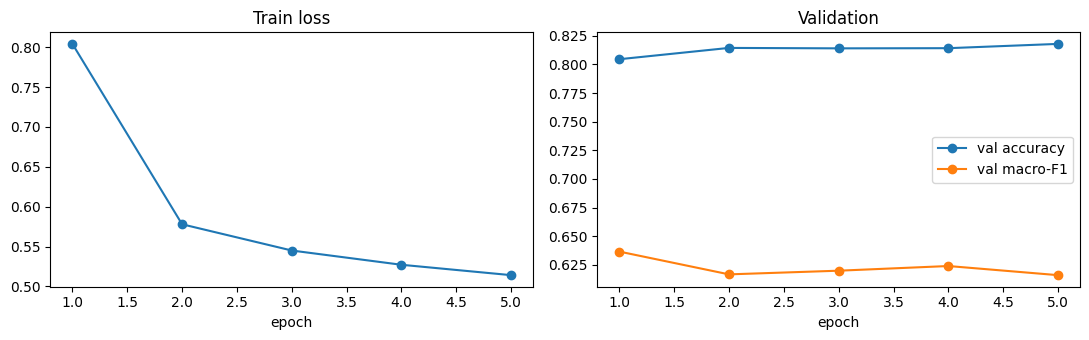

In [ ]:
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h[:, 0], h[:, 1], "o-"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h[:, 0], h[:, 2], "o-", label="val accuracy")
ax[1].plot(h[:, 0], h[:, 3], "o-", label="val macro-F1")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Validation")
plt.tight_layout(); plt.show()

## Step 6: Evaluation on unseen pitchers

### Headline numbers and confusion matrix (100 context pitches)
Look at SL / ST / FC / CU, where the hard cases are.

Arsenal Transformer: accuracy=0.8304  macro-F1=0.6244

              precision    recall  f1-score   support

          CH      0.812     0.937     0.870     31621
          CU      0.603     0.828     0.698     19807
          FC      0.692     0.775     0.731     26818
          FF      0.959     0.952     0.955     93050
          FS      0.761     0.378     0.505     10206
          KC      0.050     0.016     0.024      6316
          SI      0.936     0.945     0.940     54766
          SL      0.849     0.581     0.690     46589
          ST      0.721     0.903     0.801     29157
          SV      0.016     0.125     0.029       208

    accuracy                          0.830    318538
   macro avg      0.640     0.644     0.624    318538
weighted avg      0.833     0.830     0.823    318538



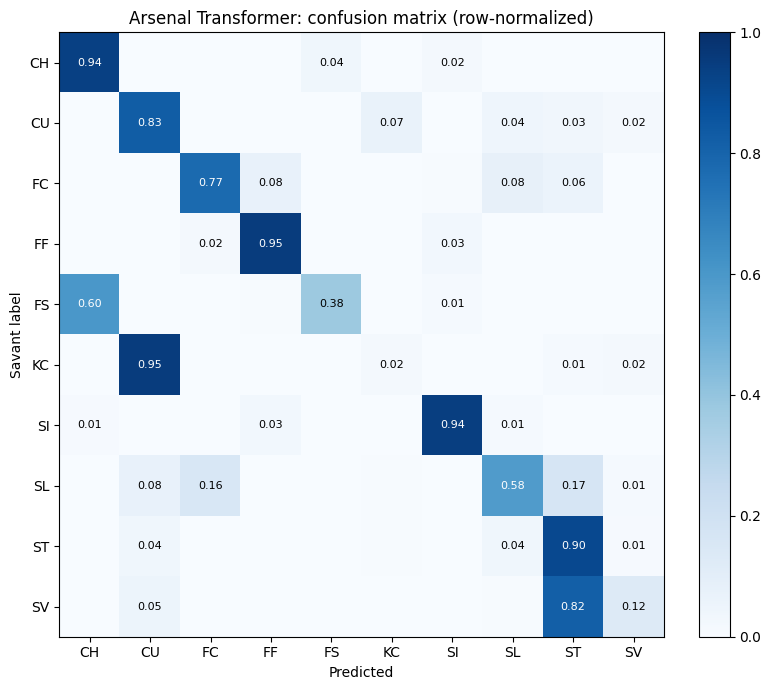

In [ ]:
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
t = splits["test"]
full_test = ArsenalDataset(t["X"], t["y"], t["g"], fixed_k=100, past_only=PAST_ONLY, seed=SEED)
y_true, y_pred = predict(model, full_test)
TF_ACC, TF_F1 = accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="macro")

#print(f"Baseline:            accuracy={BASE_ACC:.4f}  macro-F1={BASE_F1:.4f}")
print(f"Arsenal Transformer: accuracy={TF_ACC:.4f}  macro-F1={TF_F1:.4f}\n")
print(classification_report(y_true, y_pred, labels=list(range(len(CLASSES))),
                            target_names=CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)), normalize="true")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES); ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] >= 0.01:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Savant label")
ax.set_title("Arsenal Transformer: confusion matrix (row-normalized)")
fig.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=150); plt.show()

### Cold-start curve
How many pitches does the model need to "learn" a new pitcher? At `k = 0` it only sees the single pitch's physics.

context=  0: acc 0.7939  macro-F1 0.5674
context=  5: acc 0.8136  macro-F1 0.6086
context= 10: acc 0.8206  macro-F1 0.6158
context= 25: acc 0.8266  macro-F1 0.6214
context= 50: acc 0.8291  macro-F1 0.6230
context=100: acc 0.8296  macro-F1 0.6231


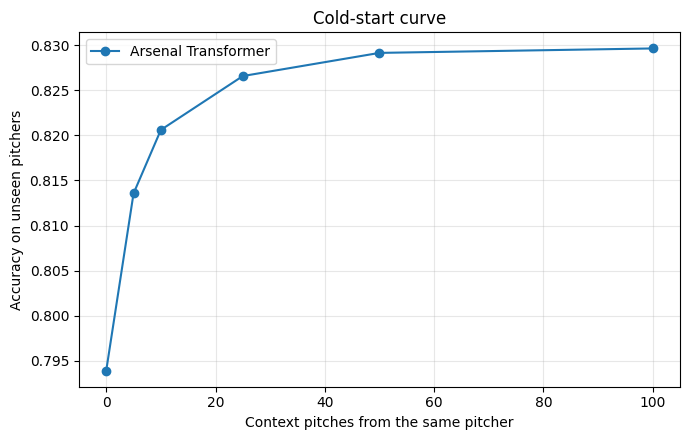

In [ ]:
curve = []
for k in [0, 5, 10, 25, 50, 100]:
    ds = subsample(ArsenalDataset(t["X"], t["y"], t["g"], fixed_k=k,
                                  past_only=PAST_ONLY, seed=SEED), EVAL_SUBSAMPLE)
    yt, yp = predict(model, ds)
    curve.append((k, accuracy_score(yt, yp), f1_score(yt, yp, average="macro")))
    print(f"context={k:>3}: acc {curve[-1][1]:.4f}  macro-F1 {curve[-1][2]:.4f}")

c = np.array(curve)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(c[:, 0], c[:, 1], "o-", label="Arsenal Transformer")
#ax.axhline(BASE_ACC, ls="--", color="gray", label=f"Gradient boosting baseline ({BASE_ACC:.3f})")
ax.set_xlabel("Context pitches from the same pitcher"); ax.set_ylabel("Accuracy on unseen pitchers")
ax.set_title("Cold-start curve"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "cold_start_curve.png", dpi=150); plt.show()

### Where do the two models disagree?
Both prediction arrays are in the same row order (test rows of `df`), so they line up directly.

In [ ]:
test_rows = df.loc[df["split"] == "test",
                   ["pitcher", "game_date", "label", "release_speed",
                    "pfx_x_in", "pfx_z_in", "release_spin_rate"]].copy()
test_rows["baseline_pred"] = [CLASSES[i] for i in base_pred]
test_rows["transformer_pred"] = [CLASSES[i] for i in y_pred]
dis = test_rows[test_rows["baseline_pred"] != test_rows["transformer_pred"]]
dis.to_csv(OUT_DIR / "disagreements.csv", index=False)

print(f"Models disagree on {len(dis):,} of {len(test_rows):,} test pitches ({len(dis)/len(test_rows):.1%})")
print("\nWho was right when they disagreed?")
print(pd.Series({
    "transformer right": (dis["transformer_pred"] == dis["label"]).sum(),
    "baseline right": (dis["baseline_pred"] == dis["label"]).sum(),
    "both wrong": ((dis["transformer_pred"] != dis["label"]) & (dis["baseline_pred"] != dis["label"])).sum(),
}))
display(pd.crosstab(dis["label"], dis["transformer_pred"]))
display(dis.sample(min(15, len(dis)), random_state=SEED))

NameError: name 'base_pred' is not defined

## Next steps
- Add a second head for whiff probability or `delta_run_exp` (a simple "stuff" model).
- Run `model.arsenal_embedding()` on each pitcher's pitches and plot with UMAP to find similar arsenals.
- Set `PAST_ONLY = True` and rerun Step 6 to see how much future pitches help.